In [1]:
# Cell 1: run OCR once (~13s/image), cache results, plot confidence distribution.
import base64
import html
import io
import os
import sqlite3
from pathlib import Path

from IPython.display import HTML, display
from PIL import Image

os.chdir(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())

from src.automate.ocr import ocr_text, parse_totals
from src.constants import CENT, MIN_CONFIDENCE
from src.db.db import get_paths

N = 500
BIN = 0.01

rows = (
    sqlite3.connect(get_paths()[0])
    .execute(
        "SELECT image_path, total_net, total_vat, total_gross FROM invoices ORDER BY id LIMIT ?",
        (N,),
    )
    .fetchall()
)

results = []  # (image, truth, ocr_totals_or_None, confidence, raw_text)
for img, *truth in rows:
    text, conf = ocr_text(img)
    try:
        # MIN_CONFIDENCE gate bypassed here: cell 2 applies your own threshold.
        o = parse_totals(text, 1.0)
        got = [o.total_net, o.total_vat, o.total_gross]
    except ValueError:
        got = None
    results.append((img, truth, got, conf, text))

confs = [r[3] for r in results]
bins = {}
for c in confs:
    b = int(c / BIN) * BIN
    bins[b] = bins.get(b, 0) + 1
peak = max(bins.values())
bars = "".join(
    f"<tr><td>{b:.2f}-{b + BIN:.2f}</td>"
    f"<td><div style='background:#4a90d9;height:14px;width:{400 * n / peak}px'></div></td>"
    f"<td>{n}</td></tr>"
    for b, n in sorted(bins.items())
)
display(
    HTML(
        f"<h3>Mean OCR confidence per invoice (n={len(confs)})</h3>"
        f"<p>min {min(confs):.3f} | median {sorted(confs)[len(confs) // 2]:.3f} | "
        f"max {max(confs):.3f} | current gate MIN_CONFIDENCE = {MIN_CONFIDENCE}</p>"
        f"<table>{bars}</table>"
    )
)

0.97-0.98,,3
0.98-0.99,,473
0.99-1.00,,9


In [10]:
# Cell 2: pick a threshold; re-run this cell only (no OCR re-run).
THRESHOLD = 0.95
SHOW = "below"  # "below" = would escalate to Tier 2, "above" = accepted by Tier 1


def correct(truth, got):
    return got is not None and all(abs(a - b) <= CENT for a, b in zip(truth, got))


above = [r for r in results if r[3] >= THRESHOLD]
below = [r for r in results if r[3] < THRESHOLD]
summary = (
    f"<h3>THRESHOLD = {THRESHOLD}</h3>"
    f"<p>accepted by Tier 1: {len(above)}/{len(results)} "
    f"({sum(correct(r[1], r[2]) for r in above)} correct)<br>"
    f"escalated to Tier 2: {len(below)}/{len(results)} "
    f"({sum(correct(r[1], r[2]) for r in below)} were actually correct = wasted LLM calls)</p>"
)
display(HTML(summary))


def img_tag(path, width=550):
    im = Image.open(path)
    im.thumbnail((width, width * 2))
    buf = io.BytesIO()
    im.save(buf, "PNG")
    return f'<img src="data:image/png;base64,{base64.b64encode(buf.getvalue()).decode()}">'


def show_invoice(img, truth, got, conf, text):
    cells = "".join(
        f"<tr><td>{name}</td><td>{t:,.2f}</td>"
        f"<td style='background:{'#d4edda' if g is not None and abs(g - t) <= CENT else '#f8d7da'}'>"
        f"{'-' if g is None else f'{g:,.2f}'}</td></tr>"
        for name, t, g in zip(["net", "VAT", "gross"], truth, got or [None] * 3)
    )
    display(
        HTML(
            f"<div style='display:flex;gap:24px;border-top:2px solid #888;padding:12px 0'>"
            f"<div>{img_tag(img)}</div><div style='min-width:360px'>"
            f"<h4>{Path(img).name} | confidence {conf:.3f}</h4>"
            f"<table><tr><th></th><th>ground truth</th><th>OCR</th></tr>{cells}</table>"
            f"<details><summary>raw OCR text</summary><pre>{html.escape(text)}</pre></details>"
            f"</div></div>"
        )
    )


for r in sorted(above if SHOW == "above" else below, key=lambda r: r[3]):
    show_invoice(*r)


In [11]:
# Cell 3: confidence by OCR outcome. Does confidence separate good reads from bad ones?
FINE_BIN = 0.002


def outcome(truth, got):
    if got is None:
        return "no_totals"  # totals row missing or failed Net + VAT == Gross
    return "exact" if correct(truth, got) else "wrong"


groups = {"exact": [], "wrong": [], "no_totals": []}
for img, truth, got, conf, _ in results:
    groups[outcome(truth, got)].append((conf, Path(img).name))

stats = "".join(
    f"<tr><td>{k}</td><td>{len(v)}</td>"
    + (
        f"<td>{min(v)[0]:.3f}</td><td>{sorted(v)[len(v) // 2][0]:.3f}</td><td>{max(v)[0]:.3f}</td>"
        if v
        else "<td>-</td><td>-</td><td>-</td>"
    )
    + "</tr>"
    for k, v in groups.items()
)

colors = {"exact": "#28a745", "wrong": "#fd7e14", "no_totals": "#dc3545"}
counts = {k: {} for k in groups}
for k, v in groups.items():
    for c, _ in v:
        b = round(int(c / FINE_BIN) * FINE_BIN, 3)
        counts[k][b] = counts[k].get(b, 0) + 1
all_bins = sorted({b for d in counts.values() for b in d})
peaks = {k: max(d.values(), default=1) for k, d in counts.items()}
hist = "".join(
    f"<tr><td>{b:.3f}-{b + FINE_BIN:.3f}</td>"
    + "".join(
        f"<td><div style='display:inline-block;background:{colors[k]};height:12px;"
        f"width:{150 * counts[k].get(b, 0) / peaks[k]}px'></div> {counts[k].get(b, '')}</td>"
        for k in groups
    )
    + "</tr>"
    for b in all_bins
)

members = "".join(
    f"<p><b>{k}</b>: " + ", ".join(f"{n} ({c:.3f})" for c, n in sorted(v)) + "</p>"
    for k, v in groups.items()
    if k != "exact"
)

display(
    HTML(
        "<h3>Confidence by outcome</h3>"
        "<table><tr><th>outcome</th><th>n</th><th>min</th><th>median</th><th>max</th></tr>"
        f"{stats}</table>"
        "<h4>Histogram (each column scaled to its own peak)</h4>"
        "<table><tr><th>confidence</th>"
        + "".join(f"<th>{k}</th>" for k in groups)
        + f"</tr>{hist}</table>{members}"
    )
)

,ground truth,OCR
net,"143,572.15","143,572.15"
VAT,"14,357.22","14,357.22"
gross,"1,579,929.37","157,929.37"

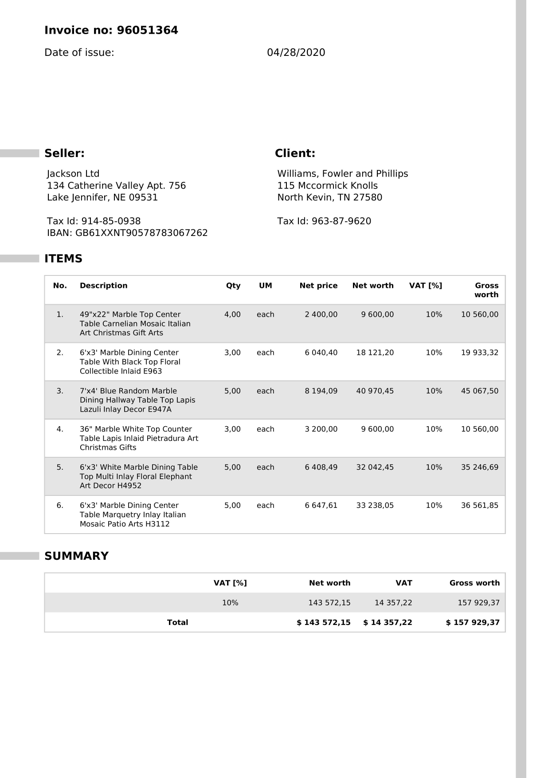

,ground truth,OCR
net,71.94,71.94
VAT,7.19,7.19
gross,0.00,79.13

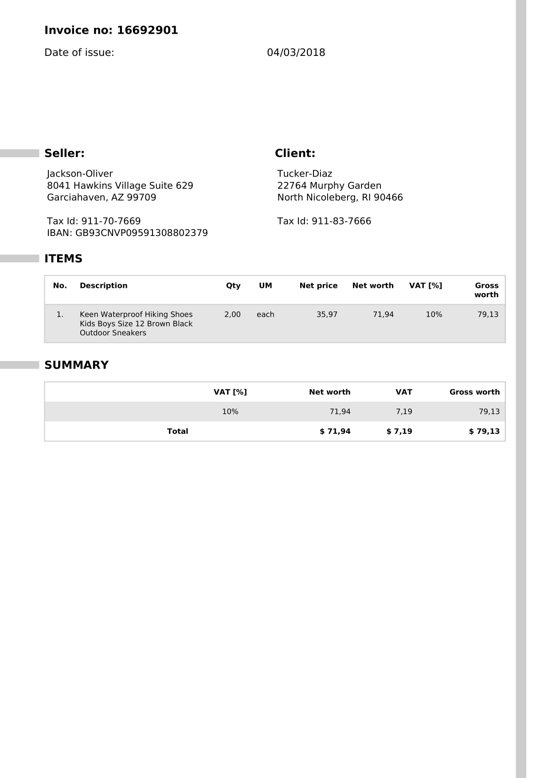

,ground truth,OCR
net,454.81,454.81
VAT,45.48,45.48
gross,0.00,500.29

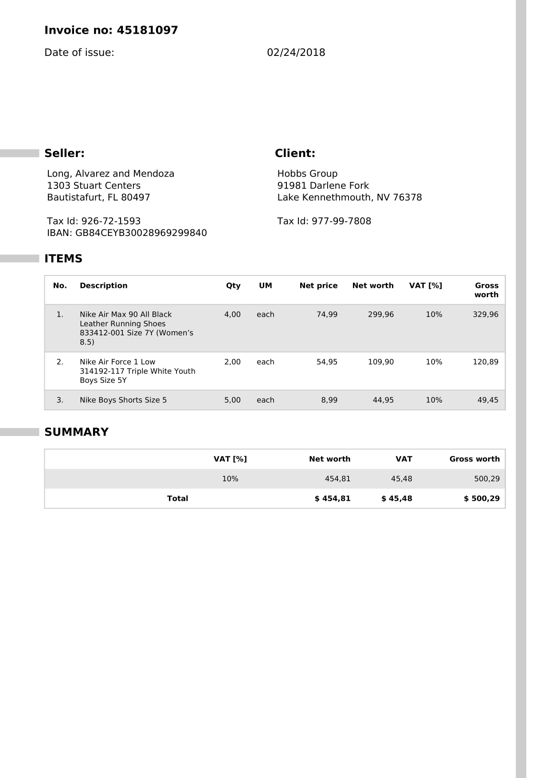

,ground truth,OCR
net,531.35,531.35
VAT,53.13,53.13
gross,0.00,584.48

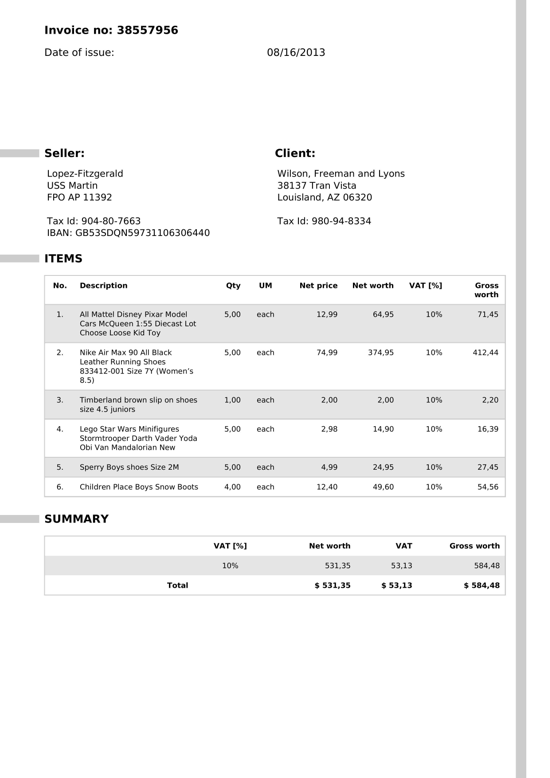

In [ ]:
# Cell 4: OCR found totals that pass the checksum but differ from ground truth.
# seems like ground truth is wrong for the following examples
EXAMPLES = 5
picked = [r for r in results if outcome(r[1], r[2]) == "wrong"]
display(HTML(f"<h3>wrong: {len(picked)} invoices, showing {min(EXAMPLES, len(picked))}</h3>"))
for r in sorted(picked, key=lambda r: r[3])[:EXAMPLES]:
    show_invoice(*r)


,ground truth,OCR
net,8.98,-
VAT,0.90,-
gross,9.88,-

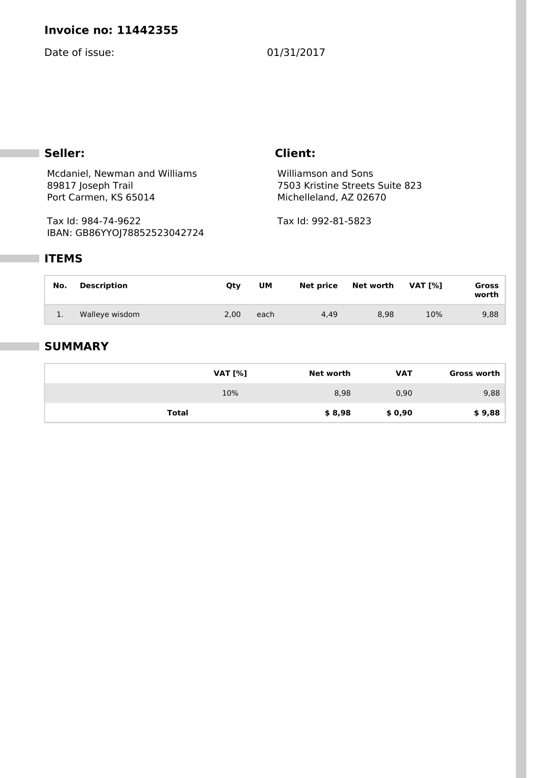

,ground truth,OCR
net,3.96,-
VAT,0.40,-
gross,4.36,-

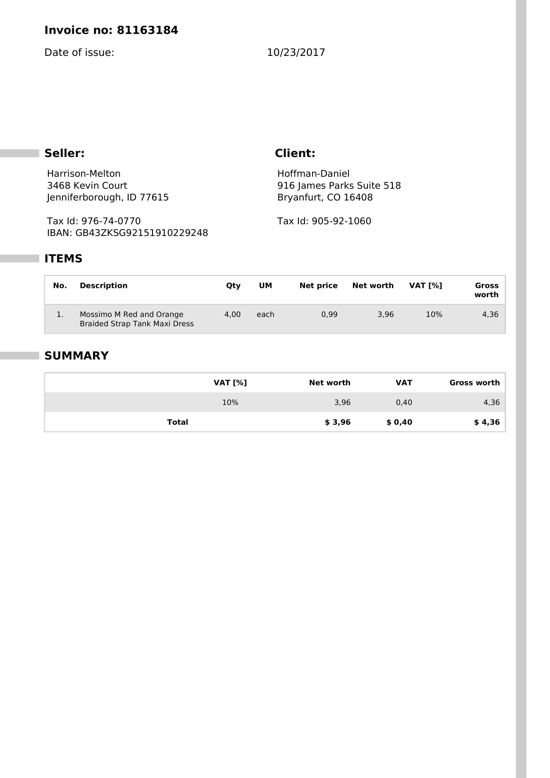

,ground truth,OCR
net,3.96,-
VAT,0.40,-
gross,4.36,-

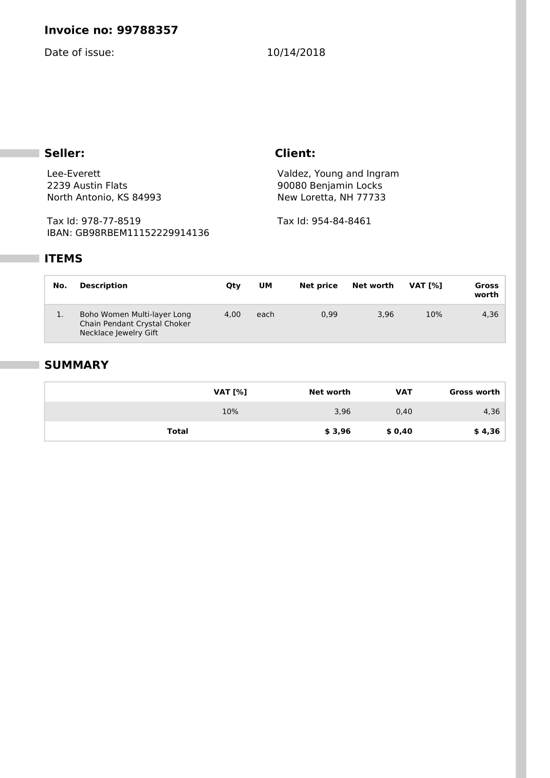

,ground truth,OCR
net,69.92,-
VAT,6.99,-
gross,76.91,-

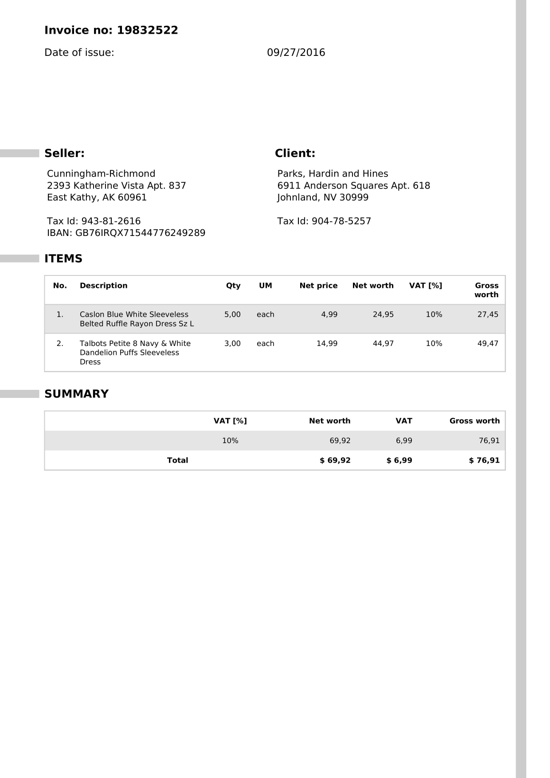

,ground truth,OCR
net,89.62,-
VAT,8.96,-
gross,98.58,-

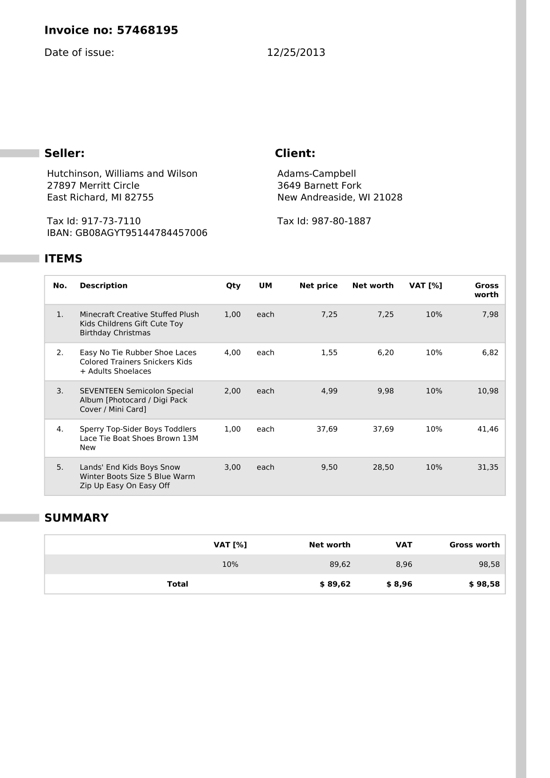

In [ ]:
# Cell 5: no totals row parsed, or it failed Net + VAT == Gross.
# something wrong with the ocr engine. can improve with regex or pass to vllm for better accuracy
EXAMPLES = 5
picked = [r for r in results if outcome(r[1], r[2]) == "no_totals"]
display(HTML(f"<h3>no_totals: {len(picked)} invoices, showing {min(EXAMPLES, len(picked))}</h3>"))
for r in sorted(picked, key=lambda r: r[3])[:EXAMPLES]:
    show_invoice(*r)
